# Hrisheek — Extra Trees

Team 6 PathSnap model experiment. Uses the shared processed arrays, loader, trainer, and scorer without changing features, labels, folds, masks, or metrics. Labels are derived reference-route proxies, not independently verified GPS truth.

Run order: inspect the initial configuration and package versions; execute the clearly marked smoke check; run all five fixed trip folds and the final student-test evaluation; review saved warnings, metrics, candidate probabilities, and final model; interpret feature importance and limitations. Results go to ignored scratch/ and results/ directories.

## Extra Trees and Random Forest

Extra Trees builds an ensemble of decision trees. At each node it samples features and random split thresholds, then selects the best among those randomized splits using the training criterion. Random Forest generally searches for the best threshold for each feature in a randomly selected feature subset. Extra Trees adds threshold randomization, which can lower variance and training cost while increasing bias.

The shared initial configuration sets 150 trees, maximum depth 24, minimum leaf size 2, two worker threads, and seed 212. The actual full parameter dictionary is printed below; scikit-learn defaults include Gini criterion, square-root feature sampling, and no bootstrap sampling. This is the initial comparison setting. No tuning is performed here.

Use the shared 10 raw features without scaling. Tree split order is invariant to monotone feature scaling, and the preprocessing decisions specify raw features for tree models.

In [ ]:
from pathlib import Path
import json
import sys
import numpy as np

ROOT = Path.cwd().resolve()
while not (ROOT / "scripts" / "model_training.py").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook with the Team 6 repository root as working directory.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import model_training

MODEL_NAME = "extra_trees"
RESULT_BASE = ROOT / "results" / "hrisheek_extra_trees_run_01"
SMOKE_BASE = ROOT / "scratch" / "hrisheek_extra_trees_smoke_01"
schema = json.loads((ROOT / "processed" / "schema.json").read_text(encoding="utf-8"))
initial_model = model_training.make_model(MODEL_NAME)
initial_config = initial_model.get_params(deep=True)
print("Repository root:", ROOT)
print("Feature order:", schema["features"])
print("Training seed:", model_training.SEED)
print("criterion:", initial_config["criterion"])
print("max_features:", initial_config["max_features"])
print("bootstrap:", initial_config["bootstrap"])
print("Complete initial estimator configuration:")
print(json.dumps(initial_config, indent=2, default=str))
print("Scaling: none; shared instructions require raw features for Extra Trees.")

Repository root: C:\Users\hrish\Downloads\Team6_training_handoff
Feature order: ['distance_m', 'heading_cos', 'heading_available', 'segment_length_m', 'projection_fraction', 'speed_mps', 'previous_gap_s', 'gps_step_m', 'candidate_distance_rank', 'distance_minus_nearest_m']
Training seed: 212
criterion: gini
max_features: sqrt
bootstrap: False
Complete initial estimator configuration:
{
  "bootstrap": false,
  "ccp_alpha": 0.0,
  "class_weight": null,
  "criterion": "gini",
  "max_depth": 24,
  "max_features": "sqrt",
  "max_leaf_nodes": null,
  "max_samples": null,
  "min_impurity_decrease": 0.0,
  "min_samples_leaf": 2,
  "min_samples_split": 2,
  "min_weight_fraction_leaf": 0.0,
  "monotonic_cst": null,
  "n_estimators": 150,
  "n_jobs": 2,
  "oob_score": false,
  "random_state": 212,
  "verbose": 0,
  "warm_start": false
}
Scaling: none; shared instructions require raw features for Extra Trees.


## Smoke check — diagnostic only

This shared-runner smoke check uses fold 0 and the first 200 eligible observations per split. Its result verifies the runtime/interface only; do not report it as a full-fold metric.

In [2]:
model_training.run(
    model_name=MODEL_NAME,
    root=str(ROOT / "processed"),
    out=str(SMOKE_BASE),
    folds=[0],
    final=False,
    smoke=True,
)
print("SMOKE CHECK COMPLETE — diagnostic only, not full-CV evidence.")

fold_0 {"split": "fold_0", "fit_seconds": 0.3770375000021886, "inference_seconds": 0.058073699998203665, "inference_ms_per_observation": 0.2903684999910183, "metrics": {"all_points": {"observations": 200, "top1_accuracy": 0.92, "macro_precision": 0.7986111111111112, "macro_recall": 0.7657407407407407, "macro_f1": 0.7790063331729998, "candidate_miss_rate": 0.0, "categorical_log_loss_with_miss_state": 0.3941184809339548}, "reliable_points": {"observations": 190, "top1_accuracy": 0.9210526315789473, "macro_precision": 0.8028169014084507, "macro_recall": 0.7659624413145539, "macro_f1": 0.7802532365912647, "candidate_miss_rate": 0.0, "categorical_log_loss_with_miss_state": 0.3850852781779266}, "reliable_coverage": 0.95, "candidate_binary_log_loss": 0.13582940993696915, "route_continuity": null, "route_continuity_reason": "Needs raw road network and an agreed path/connectivity definition; do not invent a value."}, "fit_subset_metrics": {"all_points": {"observations": 200, "top1_accuracy": 0.

SMOKE CHECK COMPLETE — diagnostic only, not full-CV evidence.


## Full experiment — five fixed trip folds and student-test

Run the shared initial comparison as prescribed. It fits each fold on the other training trips, evaluates every observation in the held-out trip fold including candidate misses, then refits on all permitted training trips and evaluates every student-test observation. The runner saves configuration, Python/NumPy/scikit-learn versions, seed, data hashes, warnings, metrics, per-split positive-class probabilities and predictions, and final model.joblib. No random candidate-row split or Bayesian search is used.

In [3]:
final_out = RESULT_BASE
model_training.run(
    model_name=MODEL_NAME,
    root=str(ROOT / "processed"),
    out=str(final_out),
    folds=[0, 1, 2, 3, 4],
    final=True,
    smoke=False,
)
print("FULL RUN COMPLETE — five trip folds plus final student-test evaluation.")

fold_0 {"split": "fold_0", "fit_seconds": 92.61737629999698, "inference_seconds": 3.2057036999904085, "inference_ms_per_observation": 0.11169699303102469, "metrics": {"all_points": {"observations": 28700, "top1_accuracy": 0.7788850174216028, "macro_precision": 0.658138909322737, "macro_recall": 0.6037244441560988, "macro_f1": 0.6203200096626458, "candidate_miss_rate": 0.00975609756097561, "categorical_log_loss_with_miss_state": 0.913729911570001}, "reliable_points": {"observations": 20087, "top1_accuracy": 0.8603574451137551, "macro_precision": 0.7607110300820419, "macro_recall": 0.7175953054785248, "macro_f1": 0.7333615095133265, "candidate_miss_rate": 0.0010952357245979987, "categorical_log_loss_with_miss_state": 0.3958923331574149}, "reliable_coverage": 0.6998954703832753, "candidate_binary_log_loss": 0.14182493638077198, "route_continuity": null, "route_continuity_reason": "Needs raw road network and an agreed path/connectivity definition; do not invent a value."}, "fit_subset_metr

fold_1 {"split": "fold_1", "fit_seconds": 81.04705310000281, "inference_seconds": 4.729923599996255, "inference_ms_per_observation": 0.11623147392726828, "metrics": {"all_points": {"observations": 40694, "top1_accuracy": 0.7526662407234481, "macro_precision": 0.7253873566502563, "macro_recall": 0.6804397797247475, "macro_f1": 0.6944876155607073, "candidate_miss_rate": 0.10217722514375584, "categorical_log_loss_with_miss_state": 3.219473606707033}, "reliable_points": {"observations": 29107, "top1_accuracy": 0.8719895557769609, "macro_precision": 0.8333720787734417, "macro_recall": 0.801188354041768, "macro_f1": 0.812872932440519, "candidate_miss_rate": 0.017177998419624144, "categorical_log_loss_with_miss_state": 0.7656259029381957}, "reliable_coverage": 0.7152651496535116, "candidate_binary_log_loss": 0.11282437815280327, "route_continuity": null, "route_continuity_reason": "Needs raw road network and an agreed path/connectivity definition; do not invent a value."}, "fit_subset_metrics

fold_2 {"split": "fold_2", "fit_seconds": 90.44785100000445, "inference_seconds": 4.3150234000058845, "inference_ms_per_observation": 0.08780009359878493, "metrics": {"all_points": {"observations": 49146, "top1_accuracy": 0.4677084605054328, "macro_precision": 0.640733880549249, "macro_recall": 0.5792581331246478, "macro_f1": 0.5991300639347156, "candidate_miss_rate": 0.28549627640092784, "categorical_log_loss_with_miss_state": 9.839265104245632}, "reliable_points": {"observations": 22542, "top1_accuracy": 0.8094667731345933, "macro_precision": 0.7519397029483484, "macro_recall": 0.6992646087556778, "macro_f1": 0.7176185033750986, "candidate_miss_rate": 0.0018188270783426493, "categorical_log_loss_with_miss_state": 0.4619721671064388}, "reliable_coverage": 0.4586741545598828, "candidate_binary_log_loss": 0.34938244484836967, "route_continuity": null, "route_continuity_reason": "Needs raw road network and an agreed path/connectivity definition; do not invent a value."}, "fit_subset_metr

fold_3 {"split": "fold_3", "fit_seconds": 69.12253269999928, "inference_seconds": 6.324728899999172, "inference_ms_per_observation": 0.10149771961355669, "metrics": {"all_points": {"observations": 62314, "top1_accuracy": 0.7515004653849857, "macro_precision": 0.6994104560689891, "macro_recall": 0.6407720385485186, "macro_f1": 0.6606204532717144, "candidate_miss_rate": 0.005632763102994512, "categorical_log_loss_with_miss_state": 0.7483121894786398}, "reliable_points": {"observations": 46757, "top1_accuracy": 0.7780225420792609, "macro_precision": 0.7580857602809893, "macro_recall": 0.7027761088366359, "macro_f1": 0.7235237881592651, "candidate_miss_rate": 0.00029942040763949784, "categorical_log_loss_with_miss_state": 0.489903108978487}, "reliable_coverage": 0.7503450267997561, "candidate_binary_log_loss": 0.13945597905195595, "route_continuity": null, "route_continuity_reason": "Needs raw road network and an agreed path/connectivity definition; do not invent a value."}, "fit_subset_me

fold_4 {"split": "fold_4", "fit_seconds": 96.45398429999477, "inference_seconds": 2.785630599988508, "inference_ms_per_observation": 0.10106412944848196, "metrics": {"all_points": {"observations": 27563, "top1_accuracy": 0.8559663316765229, "macro_precision": 0.7476711793099403, "macro_recall": 0.7055398678678954, "macro_f1": 0.7180496457787354, "candidate_miss_rate": 0.005333236585277365, "categorical_log_loss_with_miss_state": 0.5857300271649731}, "reliable_points": {"observations": 18677, "top1_accuracy": 0.9148150131177384, "macro_precision": 0.8343846549948507, "macro_recall": 0.8020468324969781, "macro_f1": 0.813942738055923, "candidate_miss_rate": 0.0005889596830326069, "categorical_log_loss_with_miss_state": 0.2670868870171636}, "reliable_coverage": 0.6776112904981315, "candidate_binary_log_loss": 0.1048521413858056, "route_continuity": null, "route_continuity_reason": "Needs raw road network and an agreed path/connectivity definition; do not invent a value."}, "fit_subset_metr

student_test {"split": "student_test", "fit_seconds": 112.76037570000335, "inference_seconds": 2.009384599994519, "inference_ms_per_observation": 0.10487393528155109, "metrics": {"all_points": {"observations": 19160, "top1_accuracy": 0.8110647181628392, "macro_precision": 0.6743191460672056, "macro_recall": 0.6157974526782923, "macro_f1": 0.6324548091156994, "candidate_miss_rate": 0.003496868475991649, "categorical_log_loss_with_miss_state": 0.6258323521229203}, "reliable_points": {"observations": 13307, "top1_accuracy": 0.8861501465394154, "macro_precision": 0.7858910786183514, "macro_recall": 0.7415024587633626, "macro_f1": 0.7571989500945207, "candidate_miss_rate": 0.0005260389268805891, "categorical_log_loss_with_miss_state": 0.30684224431691876}, "reliable_coverage": 0.6945198329853862, "candidate_binary_log_loss": 0.1199362937347207, "route_continuity": null, "route_continuity_reason": "Needs raw road network and an agreed path/connectivity definition; do not invent a value."}, "

FULL RUN COMPLETE — five trip folds plus final student-test evaluation.


In [4]:
RUN_DIR = RESULT_BASE / MODEL_NAME
records = json.loads((RUN_DIR / "metrics.json").read_text(encoding="utf-8"))
summary = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))
provenance = json.loads((RUN_DIR / "provenance.json").read_text(encoding="utf-8"))
print("Versions and seed:", {k: provenance[k] for k in ("python", "numpy", "sklearn", "seed")})
print("Completed folds:", summary["completed_folds"], "student-test completed:", summary["student_test_completed"])
print("CV Macro F1 mean/std:", summary["cv_macro_f1_mean"], summary["cv_macro_f1_std"])
for r in records:
    m = r["metrics"]
    a, rel = m["all_points"], m["reliable_points"]
    print(
        r["split"], "| fit s", round(r["fit_seconds"], 3),
        "| predict_proba s", round(r["inference_seconds"], 3),
        "| ms/observation", round(r["inference_ms_per_observation"], 4),
        "| Top-1", round(a["top1_accuracy"], 5),
        "| Macro F1", round(a["macro_f1"], 5),
        "| miss rate", round(a["candidate_miss_rate"], 5),
        "| categorical log loss with miss state", round(a["categorical_log_loss_with_miss_state"], 5),
        "| reliable coverage", round(m["reliable_coverage"], 5),
        "| reliable Macro F1", None if rel is None else round(rel["macro_f1"], 5),
        "| warnings", r["warnings"],
    )
print("Route continuity:", records[-1]["metrics"]["route_continuity"])
print("Route continuity reason:", records[-1]["metrics"]["route_continuity_reason"])

Versions and seed: {'python': '3.14.10', 'numpy': '2.5.5', 'sklearn': '1.9.1', 'seed': 212}
Completed folds: 5 student-test completed: True
CV Macro F1 mean/std: 0.6585215576417037 0.04433568259335247
fold_0 | fit s 92.617 | predict_proba s 3.206 | ms/observation 0.1117 | Top-1 0.77889 | Macro F1 0.62032 | miss rate 0.00976 | categorical log loss with miss state 0.91373 | reliable coverage 0.6999 | reliable Macro F1 0.73336 | warnings []
fold_1 | fit s 81.047 | predict_proba s 4.73 | ms/observation 0.1162 | Top-1 0.75267 | Macro F1 0.69449 | miss rate 0.10218 | categorical log loss with miss state 3.21947 | reliable coverage 0.71527 | reliable Macro F1 0.81287 | warnings []
fold_2 | fit s 90.448 | predict_proba s 4.315 | ms/observation 0.0878 | Top-1 0.46771 | Macro F1 0.59913 | miss rate 0.2855 | categorical log loss with miss state 9.83927 | reliable coverage 0.45867 | reliable Macro F1 0.71762 | warnings []
fold_3 | fit s 69.123 | predict_proba s 6.325 | ms/observation 0.1015 | Top-

## Final-model feature importance

The following plot is computed from the final all-training Extra Trees model. Impurity importance describes how the fitted trees used features in their splits. It is not causal or calibrated confidence. Correlated predictors can share or mask importance, and continuous/high-cardinality features can receive more split opportunities. Interpret it alongside the feature definitions and held-out metrics.

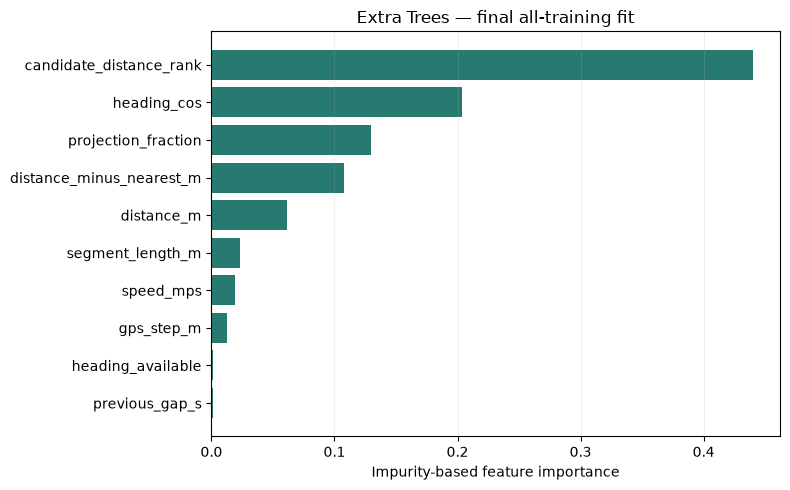

Feature importance, descending:
candidate_distance_rank        0.440075
heading_cos                    0.203495
projection_fraction            0.130055
distance_minus_nearest_m       0.108118
distance_m                     0.061214
segment_length_m               0.023402
speed_mps                      0.019064
gps_step_m                     0.012359
heading_available              0.001292
previous_gap_s                 0.000926
Importance sum: 1.0


In [5]:
import joblib
import matplotlib.pyplot as plt

final_model = joblib.load(RUN_DIR / "model.joblib")
feature_names = schema["features"]
importance = np.asarray(final_model.feature_importances_)
if len(feature_names) != len(importance):
    raise ValueError("Importance length does not match shared feature schema")
order = np.argsort(importance)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(np.asarray(feature_names)[order], importance[order], color="#267a70")
ax.set_xlabel("Impurity-based feature importance")
ax.set_title("Extra Trees — final all-training fit")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()
print("Feature importance, descending:")
for i in np.argsort(importance)[::-1]:
    print(f"{feature_names[i]:30s} {importance[i]:.6f}")
print("Importance sum:", float(importance.sum()))

In [6]:
folds = [r for r in records if r["split"].startswith("fold_")]
student = next(r for r in records if r["split"] == "student_test")
fold_f1 = np.array([r["metrics"]["all_points"]["macro_f1"] for r in folds])
fold_top1 = np.array([r["metrics"]["all_points"]["top1_accuracy"] for r in folds])
fold_miss = np.array([r["metrics"]["all_points"]["candidate_miss_rate"] for r in folds])
print(f"Five-fold Macro F1: mean={fold_f1.mean():.5f}, population std={fold_f1.std():.5f}, min={fold_f1.min():.5f}, max={fold_f1.max():.5f}")
print(f"Five-fold Top-1: mean={fold_top1.mean():.5f}, std={fold_top1.std():.5f}")
print(f"Five-fold miss rate: mean={fold_miss.mean():.5f}, max={fold_miss.max():.5f}")
print("Student-test all-point metrics:", student["metrics"]["all_points"])
print("Student-test reliable-label coverage:", student["metrics"]["reliable_coverage"])
print("Student-test timing:", {"fit_seconds": student["fit_seconds"], "inference_ms_per_observation": student["inference_ms_per_observation"]})
print("Warnings across completed full-run splits:", sum(len(r["warnings"]) for r in records))
print("Route continuity is N/A under shared scoring; do not infer it from plots.")

Five-fold Macro F1: mean=0.65852, population std=0.04434, min=0.59913, max=0.71805
Five-fold Top-1: mean=0.72135, std=0.13241
Five-fold miss rate: mean=0.08168, max=0.28550
Student-test all-point metrics: {'observations': 19160, 'top1_accuracy': 0.8110647181628392, 'macro_precision': 0.6743191460672056, 'macro_recall': 0.6157974526782923, 'macro_f1': 0.6324548091156994, 'candidate_miss_rate': 0.003496868475991649, 'categorical_log_loss_with_miss_state': 0.6258323521229203}
Student-test reliable-label coverage: 0.6945198329853862
Student-test timing: {'fit_seconds': 112.76037570000335, 'inference_ms_per_observation': 0.10487393528155109}
Warnings across completed full-run splits: 0
Route continuity is N/A under shared scoring; do not infer it from plots.


## Performance analysis and viva notes

Discuss the actual outputs above and in results/hrisheek_extra_trees_run_01/extra_trees/. Compare the five whole-trip folds with student-test. Candidate misses remain errors; report the miss rate and reliable-label coverage with Macro F1. Do not compare fitting-subset metrics directly to all-point validation without accounting for the reliable-label mask. Route continuity is explicitly N/A in the shared scorer.

Extra Trees averages randomized tree probability estimates. The shared scorer reshapes positive-class candidate scores to eight candidates per GPS observation and selects the highest-scoring road arc. The score is a binary candidate probability, not inherently a normalized categorical distribution over eight roads; use the shared scorer's declared miss-state convention. K=8 candidate generation, fixed preprocessing thresholds, and route-derived proxy labels are limitations. Results measure agreement with those proxies, not independently confirmed physical route truth.

Viva: explain the randomized threshold distinction from Random Forest; why raw features are used; the initial seed and tree settings; why whole trips are the CV unit; what candidate misses mean; how student-test is kept out of fitting; what the actual feature-importance plot can and cannot say; and why route continuity is N/A. No tuning is performed in this task. Run cells in order from the repository root after installing requirements-notebooks.txt.

In [7]:
# Create the requested analysis handoff from measured run artifacts only.
all_points = [r["metrics"]["all_points"] for r in records]
student_metrics = student["metrics"]["all_points"]
top_features = sorted(zip(feature_names, importance), key=lambda item: item[1], reverse=True)
warning_lines = [f"- {r['split']}: {w}" for r in records for w in r["warnings"]]
if not warning_lines:
    warning_lines = ["- No warnings were captured in the full experiment."]
analysis = f"""# Extra Trees — measured analysis

## Configuration and objective

The initial model is scikit-learn ExtraTreesClassifier with 150 estimators, max_depth=24,
min_samples_leaf=2, n_jobs=2, random_state=212, and the recorded defaults shown in
configuration.json (including criterion={initial_config['criterion']},
max_features={initial_config['max_features']}, bootstrap={initial_config['bootstrap']}).
The binary objective is candidate correctness. The shared runner selects the highest
positive-class probability among the eight candidates per observation.

## Cross-validation and student-test

- Five-fold all-point Macro F1: mean {summary['cv_macro_f1_mean']:.6f}, population std {summary['cv_macro_f1_std']:.6f}.
- Five-fold Top-1: mean {np.mean([m['top1_accuracy'] for m in all_points[:5]]):.6f}.
- Five-fold candidate miss rate: mean {np.mean([m['candidate_miss_rate'] for m in all_points[:5]]):.6f}.
- Student-test all-point Top-1: {student_metrics['top1_accuracy']:.6f}; Macro F1: {student_metrics['macro_f1']:.6f}.
- Student-test candidate miss rate: {student_metrics['candidate_miss_rate']:.6f}; reliable-label coverage: {student['metrics']['reliable_coverage']:.6f}.
- Student-test fit time: {student['fit_seconds']:.3f} s; predict_proba time: {student['inference_seconds']:.3f} s ({student['inference_ms_per_observation']:.4f} ms/observation).
- Route continuity: N/A under the shared scorer; no value is inferred from the map.

These are derived-proxy-label metrics. Student-test observations were not used for fitting.
Training uses only reliable proxy-labeled observations with the reference candidate present,
while evaluation retains all points. Candidate misses remain all-point errors. Interpret the
fit-subset/validation gap with that coverage difference in mind; it alone does not establish
overfitting.

## Feature importance

The final estimator's impurity-based importance is headed by:
{chr(10).join(f'- {name}: {value:.6f}' for name, value in top_features[:5])}

These values describe split-gain allocation in this fitted ensemble, not causal effects or
calibrated confidence. Correlated features can split or mask importance, and continuous or
high-cardinality features can receive more split opportunities. Importance is specific to this
dataset, label proxy, and initial estimator configuration.

## Weaknesses and interpretation

Extra Trees randomizes split thresholds as well as feature selection, unlike Random Forest's
usual search for the best threshold among selected features. This can reduce variance and fit
time while introducing bias. The fixed depth/leaf/tree settings are initial comparison settings,
not tuned values. K=8 candidates and preprocessing reliability thresholds constrain what the
classifier can learn. Route alignment labels are proxies, not independently verified truth.
Reported inference timing covers predict_proba on candidate feature rows only, not I/O,
preprocessing, candidate generation, or HMM decoding. No epoch-wise loss or route-continuity
claim is made.

## Captured warnings

{chr(10).join(warning_lines)}
"""
(RUN_DIR / "analysis.md").write_text(analysis, encoding="utf-8")
print("Wrote measured analysis:", RUN_DIR / "analysis.md")


Wrote measured analysis: C:\Users\hrish\Downloads\Team6_training_handoff\results\hrisheek_extra_trees_run_01\extra_trees\analysis.md
